In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/hour.csv')
print(df.shape)
df.head()

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [3]:
print(df.isna().sum())
print('duplicate rows:', df.duplicated().sum())

instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
duplicate rows: 0


In [4]:
print((df['casual'] + df['registered'] == df['cnt']).all())

True


In [5]:
print(df[['temp', 'atemp', 'hum', 'windspeed']].agg(['min', 'max']))
print((df['temp'] * 41).describe())

     temp  atemp  hum  windspeed
min  0.02    0.0  0.0     0.0000
max  1.00    1.0  1.0     0.8507
count    17379.000000
mean        20.376474
std          7.894801
min          0.820000
25%         13.940000
50%         20.500000
75%         27.060000
max         41.000000
Name: temp, dtype: float64


In [6]:
df['timestamp'] = pd.to_datetime(df['dteday']) + pd.to_timedelta(df['hr'], unit='h')
full = pd.date_range(df['timestamp'].min(), df['timestamp'].max(), freq='h')
missing = full.difference(df['timestamp'])

print('hours in file:', len(df))
print('hours expected:', len(full))
print('missing hours:', len(missing))
print('share missing: %.2f%%' % (100 * len(missing) / len(full)))

hours in file: 17379
hours expected: 17544
missing hours: 165
share missing: 0.94%


In [7]:
miss = pd.DataFrame({'timestamp': missing}).sort_values('timestamp').reset_index(drop=True)
miss['hr'] = miss['timestamp'].dt.hour
miss['date'] = miss['timestamp'].dt.date

print(miss['hr'].value_counts().sort_index())
print(miss['date'].value_counts().head(10))

miss['run_id'] = (miss['timestamp'].diff() != pd.Timedelta(hours=1)).cumsum()
runs = miss.groupby('run_id').size()
print('number of separate gaps:', len(runs))
print(runs.value_counts().sort_index())

hr
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3
Name: count, dtype: int64
date
2012-10-29    23
2011-01-27    16
2012-10-30    13
2011-01-18    12
2011-01-26     8
2011-08-28     7
2011-02-22     6
2011-08-27     6
2011-01-03     2
2011-01-11     2
Name: count, dtype: int64
number of separate gaps: 75
1     64
2      6
6      1
12     1
13     1
22     1
36     1
Name: count, dtype: int64


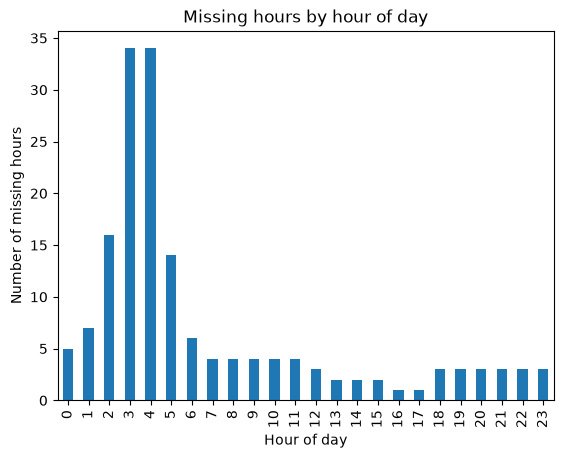

In [8]:
miss['hr'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Hour of day')
plt.ylabel('Number of missing hours')
plt.title('Missing hours by hour of day')
plt.savefig('../results/figures/missing_hours_by_hour.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
avg_by_hr = df.groupby('hr')['cnt'].mean()
print(avg_by_hr.loc[sorted(miss['hr'].unique())])

hr
0      53.898072
1      33.375691
2      22.869930
3      11.727403
4       6.352941
5      19.889819
6      76.044138
7     212.064649
8     359.011004
9     219.309491
10    173.668501
11    208.143054
12    253.315934
13    253.661180
14    240.949246
15    251.233196
16    311.983562
17    461.452055
18    425.510989
19    311.523352
20    226.030220
21    172.314560
22    131.335165
23     87.831044
Name: cnt, dtype: float64


In [10]:
long_runs = miss.groupby('run_id').agg(start=('timestamp', 'min'), end=('timestamp', 'max'), hours=('timestamp', 'size'))
long_runs[long_runs['hours'] >= 10]

,start,end,hours
run_id,,,
10,2011-01-18 00:00:00,2011-01-18 11:00:00,12
17,2011-01-26 18:00:00,2011-01-27 15:00:00,22
52,2011-08-27 18:00:00,2011-08-28 06:00:00,13
71,2012-10-29 01:00:00,2012-10-30 12:00:00,36


## Missing hours: what I found and what I decided

The file has 17,379 hourly rows, but 731 days x 24 hours = 17,544 hours should exist. So 165 hours (0.94%) are missing.

What the gaps look like:
1. Most gaps are overnight. 110 of the 165 missing hours fall between 0:00 and 5:59, and hours 3 and 4 alone have 34 each. Normal demand at these hours is tiny (about 12 bikes at 3 a.m. and 6 bikes at 4 a.m.), so a missing row here most likely means no one rented a bike, not lost data.
2. Four long gaps of 12, 22, 13 and 36 hours (18 Jan 2011, 26-27 Jan 2011, 27-28 Aug 2011 and 29-30 Oct 2012) make up 83 of the 165 missing hours. On these days demand is much lower than normal, and several of them have bad weather ratings (for example only 22 bikes in total on 29 Oct 2012). So these are probably days when the system was shut down or almost unused. I cannot confirm the cause from the data alone.
3. The two groups overlap, because the long gaps also include overnight hours. The remaining gaps are short, mostly 1 to 3 hours.

Decision: I keep the data as it is and do not fill the gaps. Filling the long gaps with 0 would put fake zeros into busy hours. The models are trained and tested only on hours that were actually recorded.

Alternative: fill only the short overnight gaps with 0.

Limitation: because the hourly timeline has holes, features that look at earlier hours (like demand one hour ago or last week) would need extra care.

## Findings from data checks

- The file has 17,379 rows and 17 columns. There are no missing values and no duplicate rows (use what your own cells 1 to 3 printed here).
- 165 hours (0.94%) are missing from the hourly timeline (17,379 present, 17,544 expected).
- 110 of the missing hours are between 0:00 and 5:59, when demand is very low, so they most likely mean zero rentals.
- Four long gaps (12, 22, 13 and 36 hours, 83 hours in total) fall on days with very low demand, so they are probably shutdowns or severe weather days.
- I do not fill the gaps. The models use only recorded hours.
- casual + registered equals cnt exactly, so both columns are left out of the features to avoid target leakage.
- temp, atemp, hum and windspeed are normalised between 0 and 1, so they are not real units.